# 1. Dataset Statistics

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy

%load_ext autoreload
%autoreload 2

from a02_helper import *
from a02_functions import normalize_data

In [2]:
# look some dataset statistics
scipy.stats.describe(X)

DescribeResult(nobs=np.int64(3065), minmax=(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 1., 1.]), array([4.5400e+00, 1.4280e+01, 5.1000e+00, 4.2810e+01, 9.0900e+00,
       3.5700e+00, 7.2700e+00, 1.1110e+01, 3.3300e+00, 1.8180e+01,
       2.0000e+00, 9.6700e+00, 5.5500e+00, 5.5500e+00, 2.8600e+00,
       1.0160e+01, 7.1400e+00, 9.0900e+00, 1.8750e+01, 6.3200e+00,
       1.1110e+01, 1.7100e+01, 5.4500e+00, 9.0900e+00, 2.0000e+01,
       1.4280e+01, 3.3330e+01, 4.7600e+00, 1.4280e+01, 4.7600e+00,
       4.7600e+00, 4.7600e+00, 1.8180e+01, 4.7600e+00, 2.0000e+01,
       7.6900e+00, 6.8900e+00, 7.4000e+00, 9.7500e+00, 4.7600e+00,
       7.1400e+00, 1.4280e+01, 3.5700e+00, 2.0000e+01, 2.1420e+01,
       1.6700e+01, 2.1200e+00, 1.0000e+01, 4.3850e+00, 9.7520e+00,
       4.0810e+00, 3.2478e+0

In [3]:
scipy.stats.describe(y)

DescribeResult(nobs=np.int64(3065), minmax=(np.int64(0), np.int64(1)), mean=np.float64(0.39738988580750406), variance=np.float64(0.23954932085067235), skewness=np.float64(0.41936632478193103), kurtosis=np.float64(-1.824131885638896))

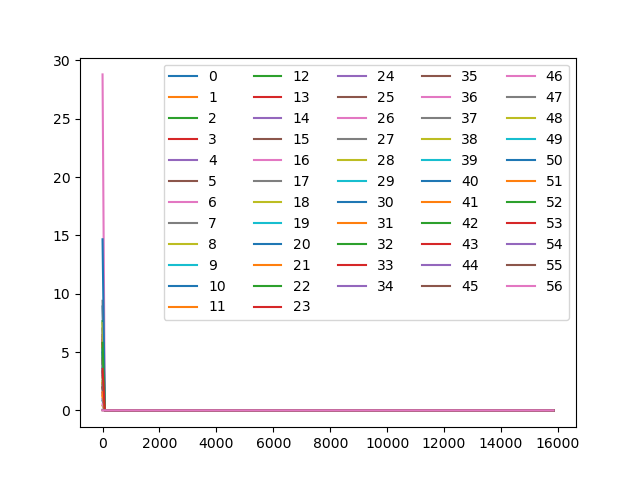

In [4]:
# plot the distribution of all features
nextplot()
densities = [scipy.stats.gaussian_kde(X[:, j]) for j in range(D)]
xs = np.linspace(0, np.max(X), 200)
for j in range(D):
    plt.plot(xs, densities[j](xs), label=j)
plt.legend(ncol=5)
plt.show()

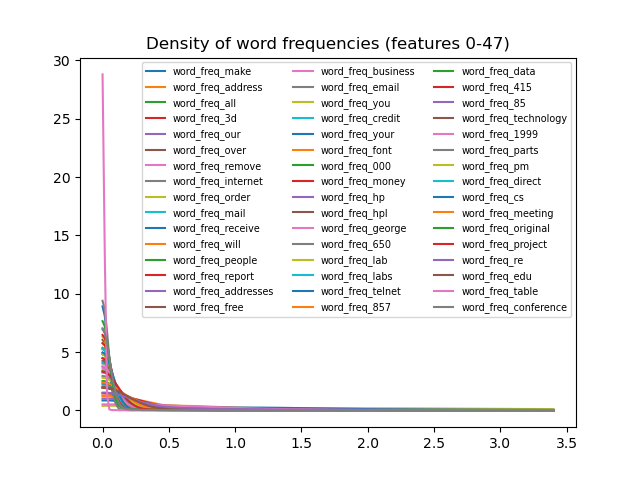

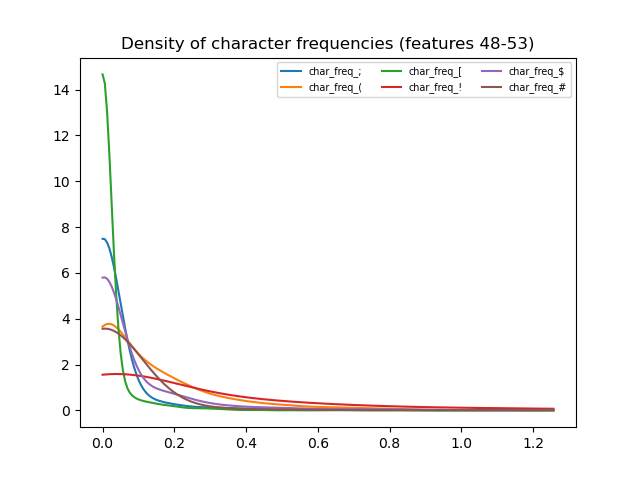

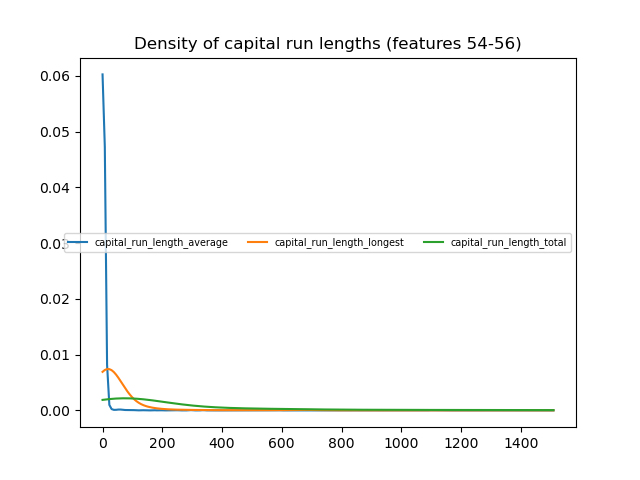

Median share of zeros per feature: 0.84


,mean,max,share_zero
capital_run_length_total,282.203915,15841.000,0.000000
capital_run_length_longest,52.675041,9989.000,0.000000
capital_run_length_average,4.900629,1102.500,0.000000
word_freq_3d,0.062969,42.810,0.988581
word_freq_george,0.771507,33.330,0.824470
char_freq_!,0.265471,32.478,0.508972
word_freq_re,0.306591,21.420,0.708972
word_freq_85,0.102157,20.000,0.897879
word_freq_hp,0.529801,20.000,0.766721
word_freq_project,0.071188,20.000,0.931811


In [5]:
# this plots is not really helpful; go now explore further
# YOUR CODE HERE
import pandas as pd

# The three feature groups live on very different scales, so plot each group separately
# and cut the x-axis at the 99th percentile of the group to see where most of the mass is.
groups = {
    "word frequencies (features 0-47)": range(0, 48),
    "character frequencies (features 48-53)": range(48, 54),
    "capital run lengths (features 54-56)": range(54, 57),
}
for title, idx in groups.items():
    idx = list(idx)
    nextplot()
    xs_group = np.linspace(0, np.percentile(X[:, idx], 99), 200)
    for j in idx:
        plt.plot(xs_group, densities[j](xs_group), label=features[j])
    plt.title(f"Density of {title}")
    plt.legend(ncol=3, fontsize="x-small")
    plt.show()

# Scale and sparsity of each feature
stats = pd.DataFrame(
    {"mean": X.mean(axis=0), "max": X.max(axis=0), "share_zero": (X == 0).mean(axis=0)},
    index=features,
)
print(f"Median share of zeros per feature: {stats['share_zero'].median():.2f}")
stats.sort_values("max", ascending=False).head(10)

In [6]:
# Let's compute z-scores; create two new variables Xz and Xtestz by completing the
# `normalize_data` function in `a02_functions.py`. Once you implemented this function, Xz and
# Xtestz will be automatically provided to you in subsequent notebooks.
Xz, Xtestz = normalize_data(X, Xtest)

In [7]:
# Let's check.
np.mean(Xz, axis=0)  # should be all 0
np.var(Xz, axis=0)  # should be all 1
np.mean(Xtestz, axis=0)  # what do you get here?
np.var(Xtestz, axis=0)

np.sum(Xz**3)  # should be: 1925261.15

np.float64(1925261.1560010156)

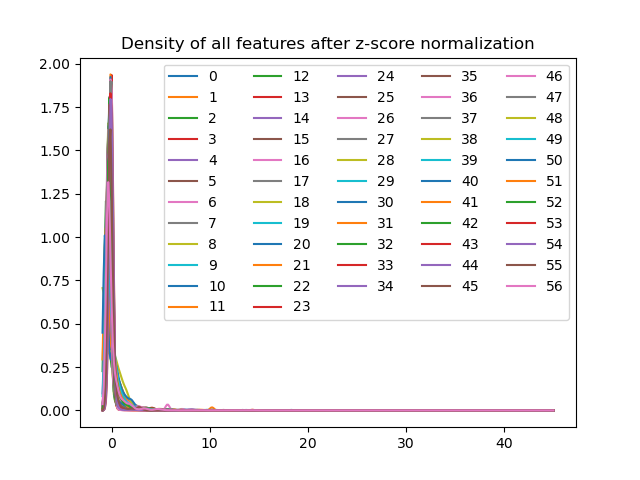

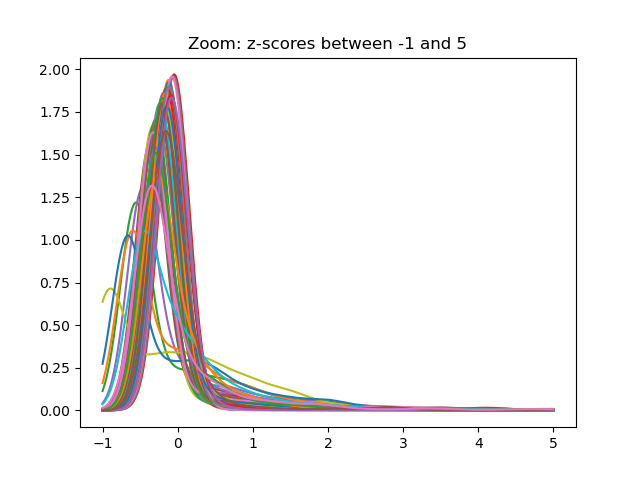

,min_z,max_z,share_zero
capital_run_length_longest,-0.234303,45.052879,0.000000
capital_run_length_average,-0.143190,40.292252,0.000000
char_freq_#,-0.102903,38.092536,0.836868
char_freq_!,-0.304730,36.976248,0.508972
word_freq_conference,-0.114565,36.398113,0.954976
word_freq_85,-0.184057,35.850310,0.897879
word_freq_parts,-0.059606,35.433426,0.983034
word_freq_project,-0.126010,35.276088,0.931811


In [8]:
# Explore the normalized data
# YOUR CODE HERE
# Same density plot as above, now on the z-scores (all features on one common scale)
nextplot()
densities_z = [scipy.stats.gaussian_kde(Xz[:, j]) for j in range(D)]
xs_z = np.linspace(np.min(Xz), np.max(Xz), 400)
for j in range(D):
    plt.plot(xs_z, densities_z[j](xs_z), label=j)
plt.legend(ncol=5)
plt.title("Density of all features after z-score normalization")
plt.show()

# Zoom into the region where most of the data lies
nextplot()
xs_zoom = np.linspace(-1, 5, 400)
for j in range(D):
    plt.plot(xs_zoom, densities_z[j](xs_zoom), label=j)
plt.title("Zoom: z-scores between -1 and 5")
plt.show()

# Features with the most extreme z-scores (outliers after normalization)
stats_z = pd.DataFrame(
    {"min_z": Xz.min(axis=0), "max_z": Xz.max(axis=0), "share_zero": (X == 0).mean(axis=0)},
    index=features,
)
stats_z.sort_values("max_z", ascending=False).head(8)